# 🛒 Online Retail II – Customer Segmentation, Repeat-Purchase Prediction & Spend Forecast

## 🎯 Business Problem
An online gift-ware shop sells to thousands of customers. The owner wants three answers:
1. **Who are my customer groups?** (VIP, regular, low value ...) → *Clustering*
2. **Which customers will buy again in the next 90 days?** → *Classification*
3. **How much will a returning customer spend in the next 90 days?** → *Regression*

With these answers the shop can send offers to the right people instead of everyone.

## 📦 Dataset
**Online Retail II** (UK online store, Dec 2009 – Dec 2011). Columns: `Invoice, StockCode, Description, Quantity, InvoiceDate, Price, Customer ID, Country`.

## 🧠 Models used
Logistic Regression, KNN, Gaussian Naive Bayes, Decision Tree, Random Forest, Linear Regression, K-Means, Hierarchical Clustering.

## 🧭 Plan of the notebook
Load → Clean → EDA (chart 1) → Feature engineering → Classification (chart 2) → Regression → Clustering (chart 3) → Conclusion

## 1. Import Important Libraries
pandas + numpy for data work, seaborn + matplotlib for the 3 charts, sklearn for models and scores.

In [56]:
import pandas as pd  # pandas: table (DataFrame) banane aur data saaf karne ke liye
import numpy as np  # numpy: array par tez maths ke liye
import matplotlib.pyplot as plt  # matplotlib: basic charts ke liye
import seaborn as sns  # seaborn: matplotlib ke upar sundar charts ke liye
import warnings  # warnings: bekaar warning messages chhupane ke liye
warnings.filterwarnings("ignore")  # warnings band kar di taaki output saaf dikhe

In [57]:
from sklearn.model_selection import train_test_split  # data ko train aur test hisson mein baantne ke liye
from sklearn.preprocessing import StandardScaler  # saare columns ko same scale par lane ke liye
from sklearn.linear_model import LogisticRegression, LinearRegression  # linear models
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor  # KNN models
from sklearn.naive_bayes import GaussianNB  # Gaussian Naive Bayes classifier
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor  # decision tree models
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor  # random forest models
from sklearn.cluster import KMeans, AgglomerativeClustering  # K-Means aur hierarchical clustering

In [58]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix  # classification ke scores
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error, r2_score  # regression ke error scores
from sklearn.metrics import silhouette_score, adjusted_rand_score  # clustering ki quality ke scores

## 2. Load the Data
Our file is an **Excel (.xlsx)** file with **two sheets** (2009-10 and 2010-11). We read each sheet and join them into one table.
Keep the file in the same folder as this notebook.
⏳ Reading ~1 million rows from Excel takes a few minutes – this is normal.

In [59]:
df_raw = pd.read_csv("online_retail_II.csv")  # csv file padhi
df_raw.shape  # rows aur columns ki ginti

(541910, 8)

In [60]:
df_raw.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,01-12-2010 08:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,01-12-2010 08:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,01-12-2010 08:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,01-12-2010 08:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,01-12-2010 08:26,3.39,17850.0,United Kingdom


In [61]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 541910 entries, 0 to 541909
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   Invoice      541910 non-null  str    
 1   StockCode    541910 non-null  str    
 2   Description  540456 non-null  str    
 3   Quantity     541910 non-null  int64  
 4   InvoiceDate  541910 non-null  str    
 5   Price        541910 non-null  float64
 6   Customer ID  406830 non-null  float64
 7   Country      541910 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 67.8 MB


In [62]:
df_raw.describe()

,Quantity,Price,Customer ID
count,541910.000000,541910.000000,406830.000000
mean,9.552234,4.611138,15287.684160
std,218.080957,96.759765,1713.603074
min,-80995.000000,-11062.060000,12346.000000
25%,1.000000,1.250000,13953.000000
50%,3.000000,2.080000,15152.000000
75%,10.000000,4.130000,16791.000000
max,80995.000000,38970.000000,18287.000000


## 3. Data Quality Check
Before cleaning we must **see the problems**: missing customers, cancelled invoices, returns and duplicates.

In [63]:
df_raw.isnull().sum()  # har column mein missing values ki ginti

Invoice             0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
Price               0
Customer ID    135080
Country             0
dtype: int64

In [64]:
df_raw.columns

Index(['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'Price', 'Customer ID', 'Country'],
      dtype='str')

In [65]:
df_raw.duplicated().sum()

np.int64(5268)

In [66]:
(df_raw['Quantity'] <= 0).sum() # zero ya negative quantity wali rows (returns)

np.int64(10624)

In [67]:
df_raw['Invoice'].astype(str).str.startswith('C').sum()   # cancel hue invoices (ye C letter se shuru hote hain)

np.int64(9288)

**Humne kya paaya:** kuch rows mein `Customer ID` nahi hai, kuch invoices cancellation hain (negative quantity) aur kuch rows duplicate hain.
Bina ID ke hum customer ko track nahi kar sakte, isliye un rows ko hatana padega. Cancelled invoices asli sales nahi hain, toh unhe bhi hata dena chahiye.

## 4. Data Cleaning
One small function does all the cleaning, so it is easy to explain step by step.

In [68]:
def clean_data(df):  # function jo raw data ko saaf karta hai
    df = df.dropna(subset=["Customer ID"]).copy()  # jin rows mein customer id nahi hai unhe hata do (customer track nahi ho sakta)
    df["Invoice"] = df["Invoice"].astype(str)  # invoice number ko text banaya taaki C letter check kar sakein
    df = df[~df["Invoice"].str.startswith("C")]  # cancel hue invoices hata diye
    df = df[(df["Quantity"] > 0) & (df["Price"] > 0)]  # sirf asli sales rakhi jinmein quantity aur price positive hai
    df = df[df["StockCode"] != "POST"]  # postage charges hata diye (ye asli product nahi hai)
    df = df.drop_duplicates()  # bilkul same duplicate rows hata di
    return df  # saaf kiya hua table wapas bhej diya

In [69]:
def fix_types(df):  # function jo data types theek karta hai aur Revenue column jodta hai
    df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], dayfirst=True)  # text ko asli date mein badla (pehle din aata hai)
    df["Customer ID"] = df["Customer ID"].astype(int)  # customer id ko poora number (integer) banaya
    df["Revenue"] = df["Quantity"] * df["Price"]  # har row par kamaya hua paisa
    return df  # table wapas bhej diya

In [70]:
df = clean_data(df_raw)  # step 1: data saaf karo
df = fix_types(df)  # step 2: types theek karo
print(df_raw.shape, "->", df.shape)  # cleaning se pehle aur baad ki rows
print(df["Customer ID"].nunique())  # unique customers ki ginti
print(df["InvoiceDate"].min(), df["InvoiceDate"].max())  # data ki pehli aur aakhri date

(541910, 8) -> (391593, 9)
4338
2010-12-01 08:26:00 2011-12-09 12:50:00


## 5. Exploratory Data Analysis (EDA)
### 📈 Chart 1 – Monthly Revenue
Shows how the business grows and when the **seasonal peak** happens (gift shops sell most before Christmas).
The last month can look low because the data stops in the middle of December.

In [71]:
def plot_monthly_revenue(df):  # function jo monthly revenue ka chart banata hai
    monthly = df.groupby(df["InvoiceDate"].dt.to_period("M"))["Revenue"].sum()  # har mahine ka total revenue
    monthly.plot(figsize=(10, 4), marker="o")  # dots ke saath line chart banaya
    plt.title("Monthly Revenue (£)")  # chart ka title
    plt.xlabel("Month")  # x axis ka label
    plt.ylabel("Revenue (£)")  # y axis ka label
    plt.show()  # chart dikhao

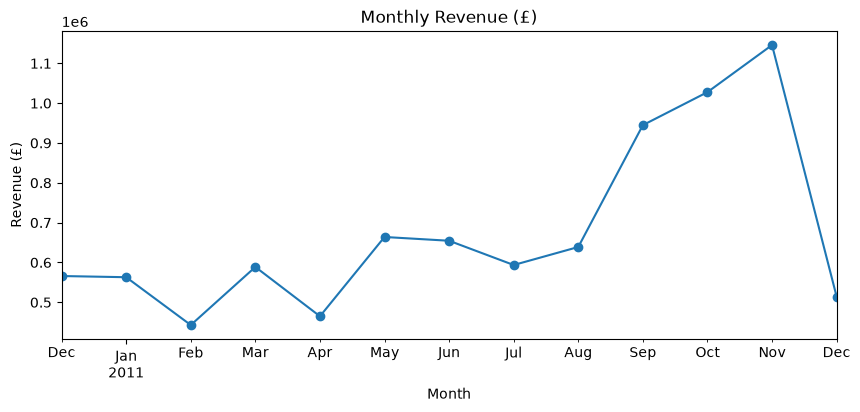

In [72]:
plot_monthly_revenue(df)  # function call karke chart 1 banao

### 💡 Two quick business facts (numbers instead of more charts)
The **Pareto rule** (80/20) – do a few customers give most of the money? And which countries matter?

In [73]:
cust_rev = df.groupby("Customer ID")["Revenue"].sum().sort_values(ascending=False)  # har customer ka total kharch, sabse zyada upar
top20 = cust_rev.head(int(len(cust_rev) * 0.2)).sum() / cust_rev.sum()  # top 20% customers se aane wale revenue ka hissa
print(f"Top 20% customers give {top20:.1%} of the revenue")  # Pareto ka result print karo

Top 20% customers give 74.7% of the revenue


In [74]:
country_rev = df.groupby("Country")["Revenue"].sum().sort_values(ascending=False)  # har country ka revenue, sabse zyada upar
(country_rev.head(5) / country_rev.sum()).round(3)  # top 5 countries ka revenue hissa

Country
United Kingdom    0.826
Netherlands       0.032
EIRE              0.030
Germany           0.024
France            0.022
Name: Revenue, dtype: float64

## 6. Feature Engineering – Har Customer Ki Ek Row Banao
Raw data mein har product line ki ek row hai. Machine learning ke liye humein **har customer ki ek row** chahiye.

⚠️ **Data leakage se bachna (interviews ke liye bahut important):**
Hum ek **cutoff date** chunte hain = **data khatam hone se 90 din pehle**.
- Features (inputs) sirf **cutoff se PEHLE ki purchases** se bante hain (past).
- Targets (jo hum predict karte hain) sirf **cutoff ke BAAD ki purchases** se bante hain (future).

Isliye model seekhte time kabhi future nahi dekhta – bilkul real life ki tarah.

In [75]:
cutoff = df["InvoiceDate"].max() - pd.Timedelta(days=90)  # hamara "aaj": data khatam hone se 90 din pehle
past = df[df["InvoiceDate"] < cutoff]  # cutoff se pehle ki purchases (features ke liye)
future = df[df["InvoiceDate"] >= cutoff]  # cutoff ke baad ki purchases (target ke liye)
print(cutoff)  # cutoff date dikhao

2011-09-10 12:50:00


### RFM features
- **Recency** – last purchase ko kitne din ho gaye (kam = active customer)
- **Frequency** – orders ki kul sankhya
- **Monetary** – kul kharch kiya hua paisa

Hum kuch aur easy features bhi add karte hain: total items, unique products, customer age, average order value, cutoff se pehle ke aakhri 90 din ka spend, aur ek UK flag.

In [76]:
def make_features(past, cutoff):  # function jo past data se har customer ki ek row banata hai
    g = past.groupby("Customer ID")  # past purchases ko customer ke hisaab se group kiya
    feat = g["Revenue"].sum().to_frame("Monetary")  # Monetary: har customer ne kul kitna paisa kharch kiya
    feat["Frequency"] = g["Invoice"].nunique()  # Frequency: orders ki ginti
    feat["Recency"] = (cutoff - g["InvoiceDate"].max()).dt.days  # Recency: aakhri purchase ko kitne din hue
    feat["TotalItems"] = g["Quantity"].sum()  # kul kitne items kharide
    feat["UniqueProducts"] = g["StockCode"].nunique()  # kitne alag-alag products kharide
    feat["CustomerAgeDays"] = (cutoff - g["InvoiceDate"].min()).dt.days  # pehli purchase ko kitne din hue
    feat["AvgOrderValue"] = feat["Monetary"] / feat["Frequency"]  # ek order ka average paisa
    return feat  # feature table wapas bhej diya

In [77]:
feat = make_features(past, cutoff)  # customer table banao
recent = past[past["InvoiceDate"] >= cutoff - pd.Timedelta(days=90)]  # cutoff se pehle ke aakhri 90 din ki purchases
feat["Spend_Last90"] = recent.groupby("Customer ID")["Revenue"].sum()  # un 90 dinon ka kharch (customer id se match hua)
feat["Spend_Last90"] = feat["Spend_Last90"].fillna(0)  # jisne recent purchase nahi ki use 0 mila
feat["IsUK"] = (past.groupby("Customer ID")["Country"].first() == "United Kingdom").astype(int)  # 1 agar customer UK ka hai

### Targets (what we want to predict) – from the FUTURE data
- `FutureSpend` – money spent in the next 90 days
- `WillBuy` – 1 if the customer bought again, else 0

In [78]:
feat["FutureSpend"] = future.groupby("Customer ID")["Revenue"].sum()  # har customer ka future kharch (customer id se match hua)
feat["FutureSpend"] = feat["FutureSpend"].fillna(0)  # jo customer dobara nahi kharide unhe 0 mila
feat["WillBuy"] = (feat["FutureSpend"] > 0).astype(int)  # 1 = dobara kharida, 0 = nahi kharida
feat.shape  # customers x columns

(3370, 11)

In [79]:
feat.head()  # customer table ki jhalak

,Monetary,Frequency,Recency,TotalItems,UniqueProducts,CustomerAgeDays,AvgOrderValue,Spend_Last90,IsUK,FutureSpend,WillBuy
Customer ID,,,,,,,,,,,
12346,77183.60,1,235,74215,1,235,77183.600,0.00,1,0.00,0
12347,2790.86,5,39,1590,82,276,558.172,584.91,0,1519.14,1
12348,1167.24,3,158,2116,21,267,389.080,0.00,0,270.00,1
12350,294.40,1,219,196,16,219,294.400,0.00,0,0.00,0
12352,1481.81,5,171,252,25,206,296.362,0.00,0,744.23,1


In [80]:
feat["WillBuy"].value_counts(normalize=True)  # kitne customers ne dobara kharida (1) aur kitno ne nahi (0), hissa

WillBuy
1    0.569733
0    0.430267
Name: proportion, dtype: float64

## 7. Part A – Classification: Will the Customer Buy Again in 90 Days?
**Target:** `WillBuy` (1 = yes, 0 = no).

**Steps:**
1. Take the log of very skewed columns (a few huge customers should not confuse the model).
2. Split 80% train / 20% test (same class ratio in both).
3. Scale the columns – the scaler learns **only from train data** (no leakage).

In [ ]:
FEATURES = ["Recency", "Frequency", "Monetary", "TotalItems", "UniqueProducts", "CustomerAgeDays", "AvgOrderValue", "Spend_Last90", "IsUK"]  # saare models ke input columns
SKEWED = ["Frequency", "Monetary", "TotalItems", "UniqueProducts", "AvgOrderValue", "Spend_Last90"]  # paise aur ginti wale columns jo bahut skewed hain

In [85]:
X = feat[FEATURES].copy()  # input table
X[SKEWED] = np.log1p(X[SKEWED])  # log(1+x) bahut bade values ka asar kam karta hai
y_class = feat["WillBuy"]  # classification ka target

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y_class, test_size=0.2, random_state=42, stratify=y_class)  # 80/20 split, class ka ratio same rakhte hue
print(X_train.shape, X_test.shape)  # dono hisson ka size

In [88]:
scaler = StandardScaler()  # scaler banaya
X_train_s = scaler.fit_transform(X_train)  # scaling train data se seekhi aur lagayi
X_test_s = scaler.transform(X_test)  # wahi scaling test data par lagayi

### Create and train the models 
Every model is **trained on the train data**. After that we measure each model on **both train data and test data**.

In [ ]:
model_lr = LogisticRegression(max_iter=1000)  # logistic regression
model_knn = KNeighborsClassifier(n_neighbors=15)  # KNN jo 15 sabse paas ke customers dekhta hai
model_nb = GaussianNB()  # Gaussian Naive Bayes
model_dt = DecisionTreeClassifier(max_depth=5, random_state=42)  # decision tree, depth limit ki taaki overfitting na ho
model_rf = RandomForestClassifier(n_estimators=200, max_depth=8, random_state=42)  # 200 trees ka random forest